In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout ,Input ,SpatialDropout1D,Bidirectional
from tensorflow.keras.callbacks import EarlyStopping ,ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import re

## 1. Load and Sample Data

In [61]:
df = pd.read_csv('/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv')

# Ensure balanced classes: 2500 positive and 2500 negative
pos_df = df[df['sentiment'] == 'positive'].sample(2500, random_state=42)
neg_df = df[df['sentiment'] == 'negative'].sample(2500, random_state=42)
df_subset = pd.concat([pos_df, neg_df]).sample(frac=1, random_state=42).reset_index(drop=True)

# SAFELY convert sentiment to binary to prevent dtype errors
df_subset['sentiment'] = df_subset['sentiment'].astype(str).str.strip().str.lower()
df_subset['sentiment'] = df_subset['sentiment'].map({'positive': 1, 'negative': 0})
labels = np.asarray(df_subset['sentiment']).astype('float32')

# Basic Text Cleaning Function
def clean_text(text):
    text = text.lower() # lowercase
    text = re.sub(r'<br />', ' ', text) # remove HTML breaks
    text = re.sub(r'[^a-zA-Z\s]', '', text) # remove punctuation/numbers
    return text

df_subset['review'] = df_subset['review'].apply(clean_text)

## 2. Tokenization and Padding

In [71]:
vocab_size = 1000 
max_length = 200    
trunc_type = 'pre'
padding_type = 'pre'
oov_tok = "<OOV>"

tokenizer = Tokenizer(num_words=vocab_size, oov_token=oov_tok)
tokenizer.fit_on_texts(df_subset['review'])

sequences = tokenizer.texts_to_sequences(df_subset['review'])
padded_sequences = pad_sequences(sequences, maxlen=max_length, padding=padding_type, truncating=trunc_type)

## 2. Text Preprocessing & Splitting (80/10/10)

In [72]:
X_train_full, X_test, y_train_full, y_test = train_test_split(padded_sequences, labels, test_size=0.2, random_state=42, stratify=labels)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full)

## 3. Define the Sequential Model (LSTM)

In [73]:
embedding_dim = 64

model = Sequential([
    Input(shape=(max_length,)), 
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    
    # SpatialDropout drops entire word embeddings, preventing over-reliance on specific words
    SpatialDropout1D(0.4), 
    
    # Removed recurrent_dropout so cuDNN GPU acceleration works again (~1 sec/epoch)
    LSTM(64, return_sequences=False),
    
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

## 5. Training

In [74]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.5086 - loss: 0.6931 - val_accuracy: 0.5125 - val_loss: 0.6919
Epoch 2/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5769 - loss: 0.6841 - val_accuracy: 0.5650 - val_loss: 0.6725
Epoch 3/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7156 - loss: 0.5749 - val_accuracy: 0.7100 - val_loss: 0.5375
Epoch 4/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8003 - loss: 0.4573 - val_accuracy: 0.7300 - val_loss: 0.5554
Epoch 5/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8272 - loss: 0.4167 - val_accuracy: 0.7800 - val_loss: 0.4935
Epoch 6/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8314 - loss: 0.4002 - val_accuracy: 0.7725 - val_loss: 0.4987
Epoch 7/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8636 - loss: 0.3419 - val_accuracy: 0.7825 - val_loss: 0.5264
Epoch 8/15
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8675 - loss: 0.3260 - val_accuracy: 0.7850 - v

## 6. Evaluation Metrics

In [75]:
y_pred_probs = model.predict(X_test)
y_pred_classes = (y_pred_probs > 0.5).astype("int32")

acc = accuracy_score(y_test, y_pred_classes)
prec = precision_score(y_test, y_pred_classes)
rec = recall_score(y_test, y_pred_classes)
f1 = f1_score(y_test, y_pred_classes)

print("\n--- Model Evaluation on 20% Test Set ---")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

--- Model Evaluation on 20% Test Set ---
Accuracy:  0.7970
Precision: 0.7839
Recall:    0.8200
F1-Score:  0.8016


## 7. Confusion Matrix Plot

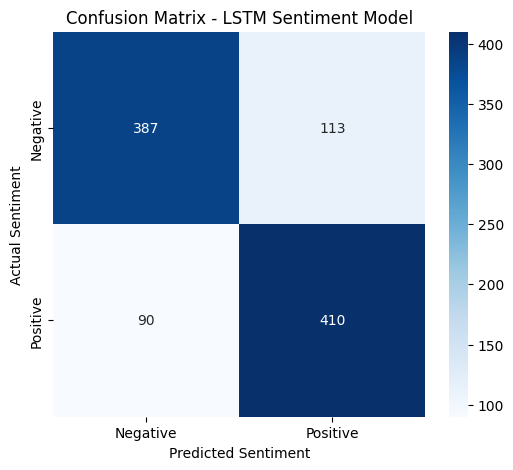

In [76]:
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.title('Confusion Matrix - LSTM Sentiment Model')
plt.ylabel('Actual Sentiment')
plt.xlabel('Predicted Sentiment')
plt.show()

## 8. Unseen Review Demonstration

In [77]:
unseen_reviews = [
    "Absolutely fantastic movie, loved the brilliant acting and stunning visuals.",
    "Terrible waste of time. The plot was boring and the acting was wooden.",
    "It was okay. Not the best I've seen, but had some funny moments.",
    "I walked out halfway through. The dialogue was incredibly cringeworthy.",
    "A masterful cinematic experience that will stay with me for a long time."
]

print("\n--- Predictions on Unseen Reviews ---")
cleaned_unseen = [clean_text(rev) for rev in unseen_reviews]
seq_unseen = tokenizer.texts_to_sequences(cleaned_unseen)
pad_unseen = pad_sequences(seq_unseen, maxlen=max_length, padding=padding_type, truncating=trunc_type)

predictions = model.predict(pad_unseen)

for i, review in enumerate(unseen_reviews):
    pred_prob = predictions[i][0]
    sentiment_label = "Positive" if pred_prob > 0.5 else "Negative"
    print(f"Review: {review}")
    print(f"Prediction: {sentiment_label} (Confidence: {pred_prob:.4f})\n")


--- Predictions on Unseen Reviews ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
Review: Absolutely fantastic movie, loved the brilliant acting and stunning visuals.
Prediction: Positive (Confidence: 0.9114)

Review: Terrible waste of time. The plot was boring and the acting was wooden.
Prediction: Negative (Confidence: 0.0584)

Review: It was okay. Not the best I've seen, but had some funny moments.
Prediction: Positive (Confidence: 0.5544)

Review: I walked out halfway through. The dialogue was incredibly cringeworthy.
Prediction: Negative (Confidence: 0.2928)

Review: A masterful cinematic experience that will stay with me for a long time.
Prediction: Positive (Confidence: 0.6345)

